In [36]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer

url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"



In [37]:
df = pd.read_csv(url)

In [38]:
df.head().T.assign(type=df.dtypes)

,0,1,2,3,4,type
lead_source,organic_search,social_media,referral,paid_ads,referral,str
industry,technology,technology,retail,manufacturing,manufacturing,str
employment_status,employed,employed,employed,student,student,str
location,europe,south_america,europe,NaN,north_america,str
annual_income,88160.0,72688.0,44697.0,NaN,24062.0,float64
number_of_courses_viewed,3,3,3,3,4,int64
interaction_count,4,7,4,6,5,int64
lead_score,0.64,0.72,0.58,0.57,0.62,float64
converted,1,1,1,0,1,int64


In [39]:
df.dtypes.to_dict()

{'lead_source': <StringDtype(storage='python', na_value=nan)>,
 'industry': <StringDtype(storage='python', na_value=nan)>,
 'employment_status': <StringDtype(storage='python', na_value=nan)>,
 'location': <StringDtype(storage='python', na_value=nan)>,
 'annual_income': dtype('float64'),
 'number_of_courses_viewed': dtype('int64'),
 'interaction_count': dtype('int64'),
 'lead_score': dtype('float64'),
 'converted': dtype('int64')}

In [40]:
from pandas.api.types import is_numeric_dtype, is_string_dtype

categorical_feature = [
    'lead_source', 'industry', 'employment_status', 'location'
]

target = ['converted']

numerical_feature = [
    col for col in df.columns
    if col not in categorical_feature + target
]

# Include the target for the dtype assertion
numeric_columns = numerical_feature + target

for col_name, col_type in df.dtypes.items():
    if is_string_dtype(col_type) or isinstance(col_type, pd.CategoricalDtype):
        assert col_name in categorical_feature, f"{col_name} should be categorical"
    elif is_numeric_dtype(col_type):
        assert col_name in numeric_columns, f"{col_name} should be numerical"

In [41]:
df.isnull().sum(0)

/tmp/ipykernel_6297/1381888268.py:1: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  df.isnull().sum(0)


lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [42]:
df[categorical_feature] = df[categorical_feature].fillna("NA")
df[numerical_feature] = df[numerical_feature].fillna(0.0)
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

<Axes: >

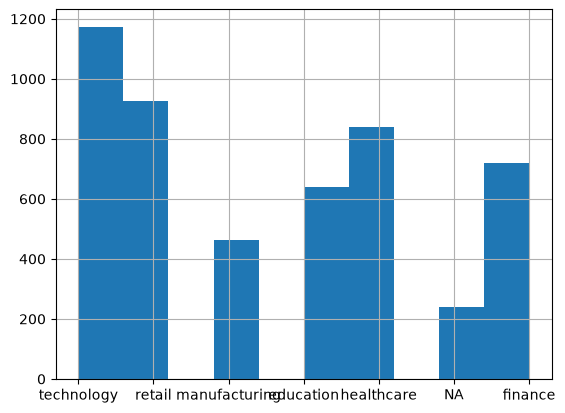

In [43]:
df['industry'].hist()

In [44]:
df['industry'].mode()

0    technology
Name: industry, dtype: str

In [45]:
corr = df[numerical_feature].corr()
mask = np.tril(np.ones_like(corr, dtype=bool))
corr.where(~mask).stack().idxmax()

('interaction_count', 'lead_score')

In [46]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)
df_train_x = df_train.drop(columns=target)
df_train_y = df_train[target[0]]

df_val_x = df_val.drop(columns=target)
df_val_y = df_val[target[0]]

In [47]:
mi_res = {}
for col in categorical_feature:
    mi = mutual_info_score(df_train[col],df_train[target[0]])
    mi_res[col]= mi
mi_res

{'lead_source': 0.03434605791617973,
 'industry': 0.0019945636715935217,
 'employment_status': 0.018965604906982875,
 'location': 0.001042763579701525}

In [48]:
max(mi_res, key=mi_res.get)

'lead_source'

In [73]:
def train(
    df_train_x,
    df_train_y,
    df_val_x,
    df_val_y,
    exclude_col=None,
    C=1.0,
):
    if exclude_col is not None:
        df_train_x = df_train_x.drop(columns=exclude_col)
        df_val_x = df_val_x.drop(columns=exclude_col)

    vec = DictVectorizer(sparse=False)
    X_train = vec.fit_transform(df_train_x.to_dict(orient="records"))
    X_val = vec.transform(df_val_x.to_dict(orient="records"))

    model = LogisticRegression(
        solver="liblinear",
        C=C,
        max_iter=1000,
        random_state=42,
    )
    model.fit(X_train, df_train_y)

    return (model.predict(X_val) == df_val_y).mean()
acc_with_all = train(df_train_x=df_train_x,df_train_y=df_train_y,
      df_val_x=df_val_x,df_val_y=df_val_y)
acc_with_all

np.float64(0.645)

In [74]:
acc_exclude={}
difference= {}
for col in df_train_x.columns:
    acc_temp=train(df_train_x=df_train_x,df_train_y=df_train_y,
      df_val_x=df_val_x,df_val_y=df_val_y,exclude_col=col)
    acc_exclude[col]=acc_temp
    difference[col] = acc_with_all - acc_temp

In [75]:
acc_exclude

{'lead_source': np.float64(0.642),
 'industry': np.float64(0.645),
 'employment_status': np.float64(0.645),
 'location': np.float64(0.645),
 'annual_income': np.float64(0.724),
 'number_of_courses_viewed': np.float64(0.643),
 'interaction_count': np.float64(0.601),
 'lead_score': np.float64(0.644)}

In [76]:
sorted(difference.items(), key=lambda x: x[1])

[('annual_income', np.float64(-0.07899999999999996)),
 ('industry', np.float64(0.0)),
 ('employment_status', np.float64(0.0)),
 ('location', np.float64(0.0)),
 ('lead_score', np.float64(0.0010000000000000009)),
 ('number_of_courses_viewed', np.float64(0.0020000000000000018)),
 ('lead_source', np.float64(0.0030000000000000027)),
 ('interaction_count', np.float64(0.04400000000000004))]

In [ ]:
scores = {
    C: round(
        train(df_train_x, df_train_y, df_val_x, df_val_y, C=C),
        3,
    )
    for C in [0.000001, 0.00001, 0.0001, 0.001]
}

# Highest rounded accuracy, then smallest C in case of a tie
best_C = min(scores, key=lambda C: (-scores[C], C))

scores, best_C

({1e-06: np.float64(0.598),
  1e-05: np.float64(0.598),
  0.0001: np.float64(0.613),
  0.001: np.float64(0.645),
  0.1: np.float64(0.645),
  1: np.float64(0.645)},
 0.001)